# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

df = pd.read_csv(DATA_PATH)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print("Forma:", df.shape)
print("\nTipos de dato:")
print(df.dtypes.value_counts())

print("\nNulos totales:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))

print("\nDistribución del target (conteo):")
print(df["target"].value_counts().sort_index())
print("\nDistribución del target (proporción):")
print(df["target"].value_counts(normalize=True).sort_index().round(3))

df.describe().T[["min", "mean", "max", "std"]].round(2)

Forma: (178, 14)

Tipos de dato:
float64    13
int64       1
Name: count, dtype: int64

Nulos totales: 0
Filas duplicadas: 0

Distribución del target (conteo):
target
0    59
1    71
2    48
Name: count, dtype: int64

Distribución del target (proporción):
target
0    0.331
1    0.399
2    0.270
Name: proportion, dtype: float64


,min,mean,max,std
alcohol,11.03,13.00,14.83,0.81
malic_acid,0.74,2.34,5.80,1.12
ash,1.36,2.37,3.23,0.27
alcalinity_of_ash,10.60,19.49,30.00,3.34
magnesium,70.00,99.74,162.00,14.28
total_phenols,0.98,2.30,3.88,0.63
flavanoids,0.34,2.03,5.08,1.00
nonflavanoid_phenols,0.13,0.36,0.66,0.12
proanthocyanins,0.41,1.59,3.58,0.57
color_intensity,1.28,5.06,13.00,2.32


**Conclusión de calidad:**

> El dataset tiene 178 filas y 13 variables numéricas más el `target` (3 clases de vino). No hay valores nulos ni filas duplicadas, así que no hizo falta imputar ni eliminar nada. Las clases están algo desbalanceadas pero no de forma grave (59, 71 y 48 muestras, es decir 33 %, 40 % y 27 %), por eso decidí que el split sea **estratificado** para conservar esas proporciones en train y test. Las variables están en escalas muy distintas (por ejemplo `proline` llega a 1680 y `hue` no pasa de 1.7), lo que me dice que más adelante hay que escalar para los modelos sensibles a la escala (regresión logística y KNN). Como el dataset es pequeño (178 filas), el test de 20 % tendrá solo 36 muestras, así que hay que tener cuidado al interpretar su accuracy.

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

In [6]:
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

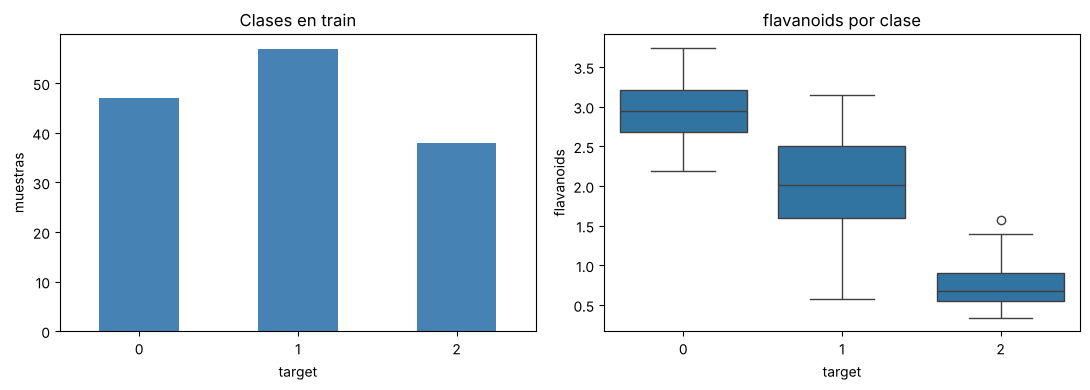

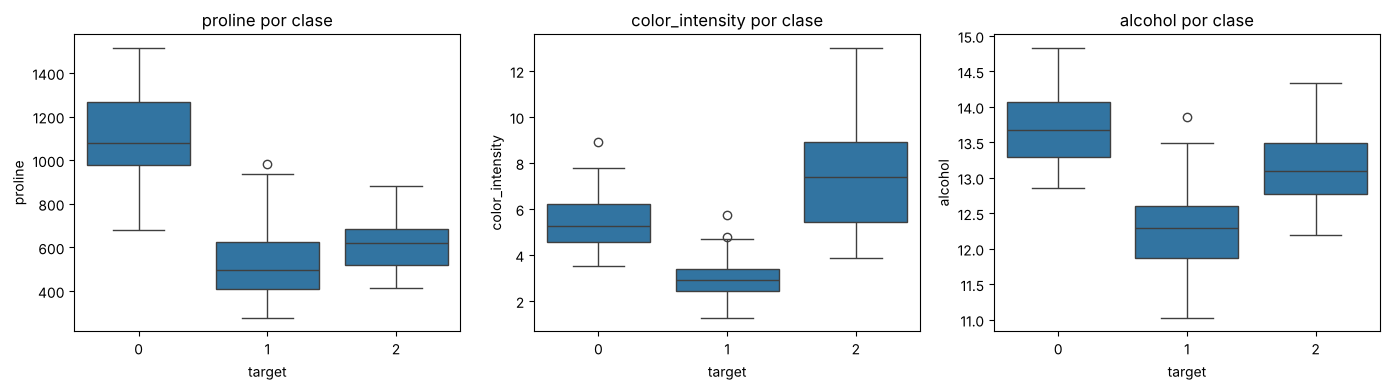

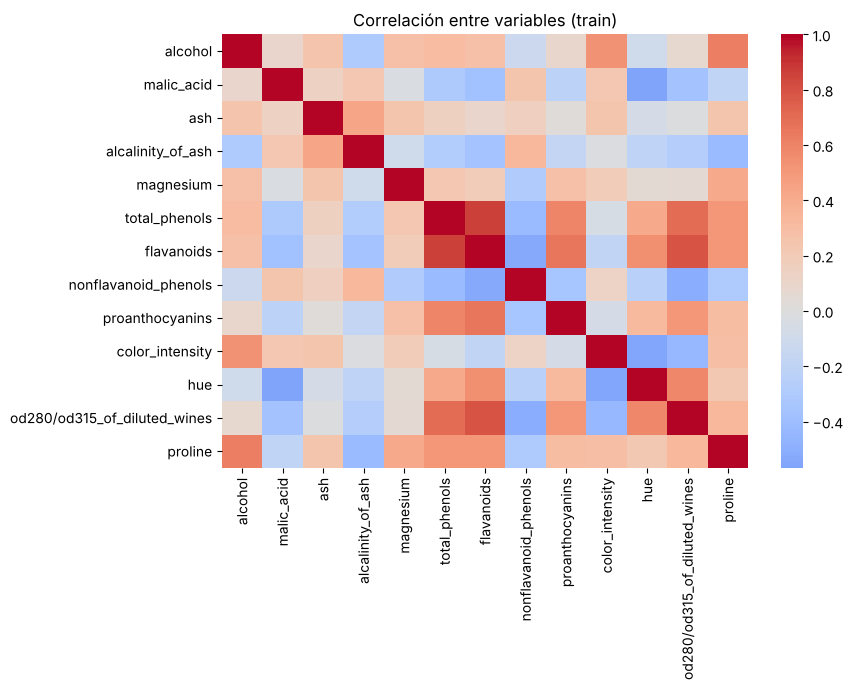

Pares más correlacionados:
total_phenols                 flavanoids                      0.86
od280/od315_of_diluted_wines  flavanoids                      0.79
total_phenols                 od280/od315_of_diluted_wines    0.69
dtype: float64

Correlación absoluta con el target:
flavanoids                      0.87
od280/od315_of_diluted_wines    0.78
total_phenols                   0.71
proline                         0.64
hue                             0.61
dtype: float64

Medias por clase:
        flavanoids  proline  color_intensity  alcohol
target                                               
0             2.93  1092.34             5.48    13.70
1             2.01   526.25             2.98    12.28
2             0.78   622.89             7.39    13.11


In [7]:
features = [c for c in train_df.columns if c != "target"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train_df["target"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Clases en train")
axes[0].set_xlabel("target")
axes[0].set_ylabel("muestras")
axes[0].tick_params(axis="x", rotation=0)

sns.boxplot(data=train_df, x="target", y="flavanoids", ax=axes[1])
axes[1].set_title("flavanoids por clase")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["proline", "color_intensity", "alcohol"]):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax)
    ax.set_title(f"{col} por clase")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(train_df[features].corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlación entre variables (train)")
plt.tight_layout()
plt.show()

corr_pairs = (
    train_df[features].corr().abs()
    .where(~np.eye(len(features), dtype=bool))
    .stack().sort_values(ascending=False)
)
print("Pares más correlacionados:")
print(corr_pairs.iloc[::2].head(3).round(2))
print("\nCorrelación absoluta con el target:")
print(train_df[features].corrwith(train_df["target"]).abs().sort_values(ascending=False).head(5).round(2))
print("\nMedias por clase:")
print(train_df.groupby("target")[["flavanoids", "proline", "color_intensity", "alcohol"]].mean().round(2))

**Hallazgos:**

1. **Hay variables que separan bien las clases por sí solas.** `flavanoids` es la que más se relaciona con el target (correlación absoluta de 0.87) y sus medias son muy distintas por clase (2.93, 2.01 y 0.78). `proline` separa muy bien la clase 0 (media ≈ 1092) de las otras dos (≈ 526 y ≈ 623), y `color_intensity` distingue la clase 2 (≈ 7.4) de las demás. Esto hace pensar que incluso modelos simples van a funcionar bastante bien.
2. **Hay variables fuertemente correlacionadas entre sí**, como `total_phenols` con `flavanoids` (0.86) y `od280/od315_of_diluted_wines` con `flavanoids` (0.79). Hay información redundante, lo que no es grave para árboles pero sí puede afectar la interpretación de los coeficientes de la regresión logística (multicolinealidad).
3. **Las escalas son muy diferentes**: `proline` tiene una desviación estándar de ≈ 301 mientras la mayoría de variables está en el rango de decenas o unidades. Para KNN (que usa distancias) y para la regresión logística hay que estandarizar dentro del pipeline; si no, `proline` dominaría el resultado.

## 4. Persistencia de datos y contrato

In [8]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

contract = {
    "target": "target",
    "features": [c for c in df.columns if c != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
}
(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(contract, indent=2), encoding="utf-8"
)
print("Guardado:", list(contract.keys()))

Guardado: ['target', 'features', 'random_state', 'test_size']


In [9]:
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.

---
### Declaración de uso de IA generativa

Herramienta: Claude (Anthropic). Propósito: asistencia en programación (carga, split, gráficas y guardado de artefactos) y borrador de los textos de conclusión y hallazgos, que contrasté con las salidas del notebook.